# **Vanilla KNN**



Model Training Accuracy (k=5): 96.67%
Model Test Accuracy (k=5):     95.00%


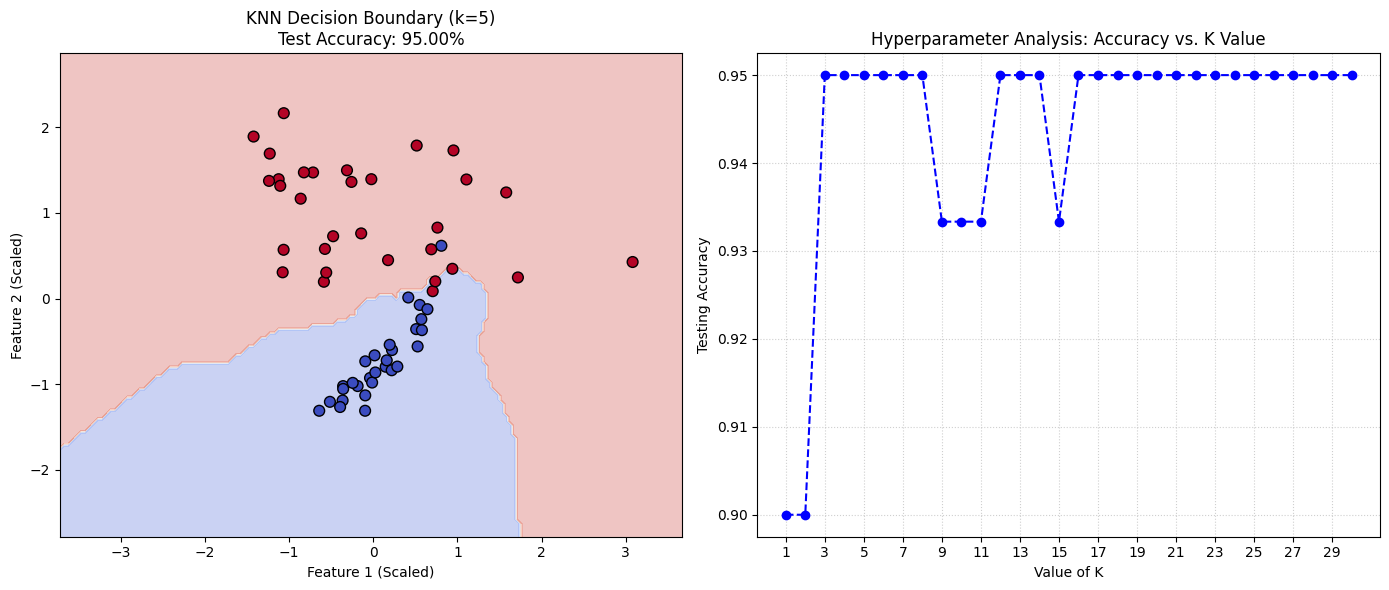

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ==========================================
# 1. Custom K-Nearest Neighbors Implementation
# ==========================================

class KNNClassifier:
    """
    K-Nearest Neighbors Classifier implemented from scratch.
    """
    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        """
        Store the training data. KNN is a lazy learner and requires no explicit training phase.
        """
        self.X_train = np.array(X)
        self.y_train = np.array(y)

    def _euclidean_distance(self, x1, x2):
        """
        Calculate Euclidean Distance between two data points: sqrt(sum((x1 - x2)^2))
        """
        return np.sqrt(np.sum((x1 - x2) ** 2))

    def _predict_single(self, x):
        """
        Helper method to predict the label for a single data point.
        """
        # Step 1: Compute distances between input x and all points in the training set
        distances = [self._euclidean_distance(x, x_train) for x_train in self.X_train]

        # Step 2: Get indices of the k nearest neighbors
        k_indices = np.argsort(distances)[:self.k]

        # Step 3: Get the labels of the k nearest neighbors
        k_nearest_labels = [self.y_train[i] for i in k_indices]

        # Step 4: Perform a majority vote to get the most common class
        most_common = Counter(k_nearest_labels).most_common(1)
        return most_common[0][0]

    def predict(self, X):
        """
        Predict class labels for a dataset of samples.
        """
        X = np.array(X)
        return np.array([self._predict_single(x) for x in X])

    def score(self, X, y):
        """
        Calculate classification accuracy.
        """
        predictions = self.predict(X)
        return np.mean(predictions == y)


# ==========================================
# 2. Dataset Generation and Preprocessing
# ==========================================

# Generate synthetic 2D binary classification data
X, y = make_classification(
    n_samples=300,
    n_features=2,
    n_redundant=0,
    n_clusters_per_class=1,
    random_state=42
)

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Feature Scaling (Crucial for distance-based algorithms like KNN)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# ==========================================
# 3. Model Evaluation & Result Visualization
# ==========================================

# Instantiate and fit KNN classifier
k_value = 5
knn = KNNClassifier(k=k_value)
knn.fit(X_train, y_train)

# Calculate accuracy
train_acc = knn.score(X_train, y_train)
test_acc = knn.score(X_test, y_test)
print(f"Model Training Accuracy (k={k_value}): {train_acc * 100:.2f}%")
print(f"Model Test Accuracy (k={k_value}):     {test_acc * 100:.2f}%")

# Create diagnostic visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Decision Boundary Visualization
x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                     np.arange(y_min, y_max, 0.05))

# Predict background grid points to construct decision regions
grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = knn.predict(grid_points)
Z = Z.reshape(xx.shape)

# Contour plot of decision boundary
axes[0].contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
scatter = axes[0].scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=plt.cm.coolwarm, edgecolors='k', s=60)
axes[0].set_title(f"KNN Decision Boundary (k={k_value})\nTest Accuracy: {test_acc * 100:.2f}%")
axes[0].set_xlabel("Feature 1 (Scaled)")
axes[0].set_ylabel("Feature 2 (Scaled)")

# Plot 2: Accuracy vs. K Value Analysis
k_values = range(1, 31)
accuracies = []

for k in k_values:
    model = KNNClassifier(k=k)
    model.fit(X_train, y_train)
    accuracies.append(model.score(X_test, y_test))

axes[1].plot(k_values, accuracies, marker='o', linestyle='--', color='b')
axes[1].set_title("Hyperparameter Analysis: Accuracy vs. K Value")
axes[1].set_xlabel("Value of K")
axes[1].set_ylabel("Testing Accuracy")
axes[1].set_xticks(range(1, 31, 2))
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# **Distance-Weighted K-Nearest Neighbors**

Distance-Weighted KNN Test Accuracy (k=5): 91.67%


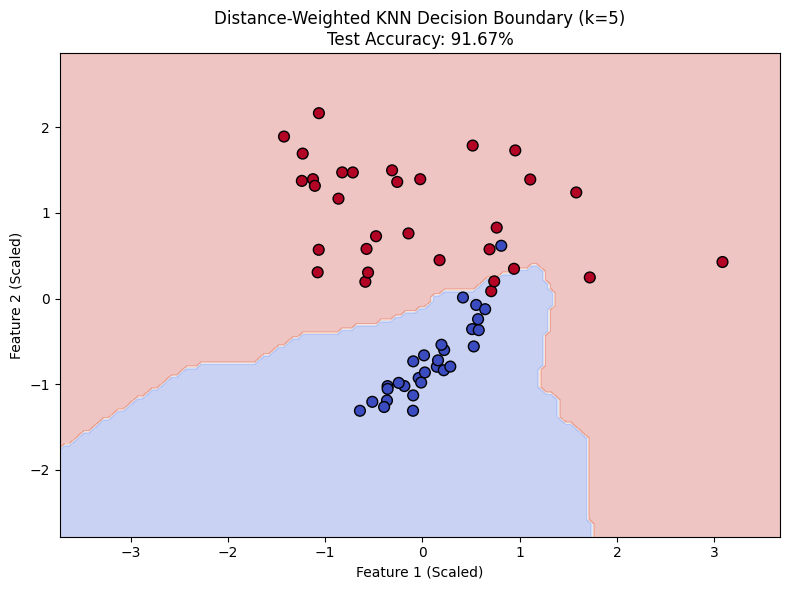

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ============================================================
# 1. Distance-Weighted K-Nearest Neighbors Implementation
# ============================================================

class DistanceWeightedKNN:
    """
    K-Nearest Neighbors Classifier with Distance-Weighted Voting.
    Points closer to the query sample exert higher influence on the decision.
    """
    def __init__(self, k=5, epsilon=1e-5):
        self.k = k
        self.epsilon = epsilon  # Small constant to prevent Division-by-Zero error

    def fit(self, X, y):
        """
        Store training data (lazy learner).
        """
        self.X_train = np.array(X)
        self.y_train = np.array(y)

    def _euclidean_distance(self, x1, x2):
        """
        Calculate Euclidean distance between two points.
        """
        return np.sqrt(np.sum((x1 - x2) ** 2))

    def _predict_single(self, x):
        """
        Predict label for a single point using inverse-distance weighting.
        """
        # Step 1: Compute Euclidean distances to all training points
        distances = [self._euclidean_distance(x, x_train) for x_train in self.X_train]

        # Step 2: Identify indices of the k nearest neighbors
        k_indices = np.argsort(distances)[:self.k]

        # Step 3: Get distances and labels for the top k neighbors
        k_distances = [distances[i] for i in k_indices]
        k_nearest_labels = [self.y_train[i] for i in k_indices]

        # Step 4: Calculate inverse distance weights: w_i = 1 / (d_i + epsilon)
        weights = [1.0 / (d + self.epsilon) for d in k_distances]

        # Step 5: Accumulate weights per class label
        class_weights = defaultdict(float)
        for label, weight in zip(k_nearest_labels, weights):
            class_weights[label] += weight

        # Step 6: Pick the class with the highest total weight
        return max(class_weights, key=class_weights.get)

    def predict(self, X):
        """
        Predict class labels for a dataset.
        """
        X = np.array(X)
        return np.array([self._predict_single(x) for x in X])

    def score(self, X, y):
        """
        Calculate accuracy score.
        """
        predictions = self.predict(X)
        return np.mean(predictions == y)


# ============================================================
# 2. Data Preparation
# ============================================================

X, y = make_classification(
    n_samples=300,
    n_features=2,
    n_redundant=0,
    n_clusters_per_class=1,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# ============================================================
# 3. Model Comparison & Visualization
# ============================================================

k_value = 5
weighted_knn = DistanceWeightedKNN(k=k_value)
weighted_knn.fit(X_train, y_train)

test_acc = weighted_knn.score(X_test, y_test)
print(f"Distance-Weighted KNN Test Accuracy (k={k_value}): {test_acc * 100:.2f}%")

# Plot Decision Boundaries
fig, ax = plt.subplots(figsize=(8, 6))

x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                     np.arange(y_min, y_max, 0.05))

grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = weighted_knn.predict(grid_points)
Z = Z.reshape(xx.shape)

ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=plt.cm.coolwarm, edgecolors='k', s=60)
ax.set_title(f"Distance-Weighted KNN Decision Boundary (k={k_value})\nTest Accuracy: {test_acc * 100:.2f}%")
ax.set_xlabel("Feature 1 (Scaled)")
ax.set_ylabel("Feature 2 (Scaled)")

plt.tight_layout()
plt.show()

# **Comparision of Custom KNN  with Uniform vs. Distance Appraoch**

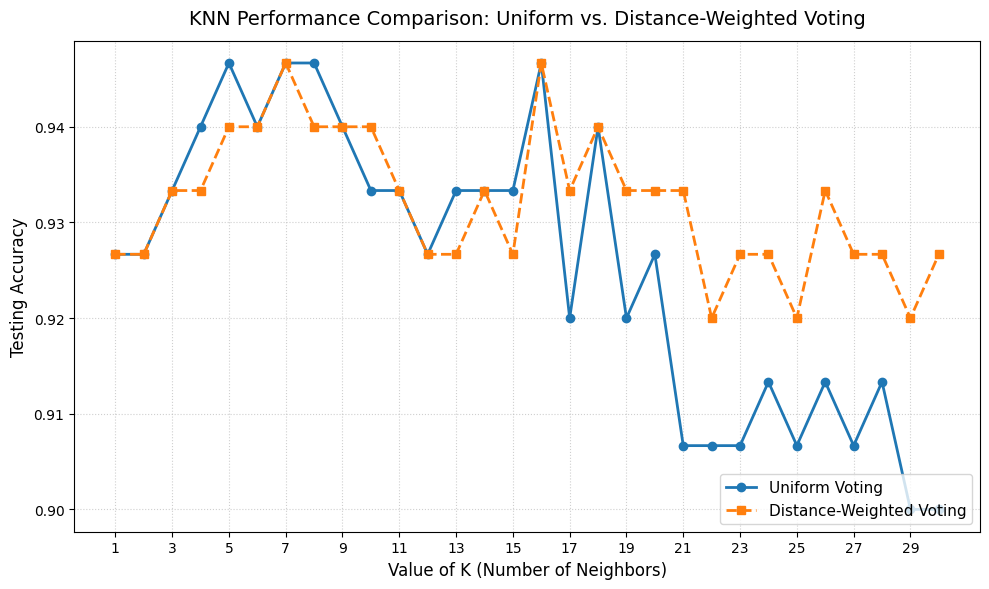

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ============================================================
# 1. Flexible Custom KNN Implementation (Uniform vs. Distance)
# ============================================================

class KNNClassifier:
    """
    K-Nearest Neighbors Classifier supporting both 'uniform' and 'distance'-weighted voting.
    """
    def __init__(self, k=5, weights='uniform', epsilon=1e-5):
        self.k = k
        self.weights = weights
        self.epsilon = epsilon  # Avoid division by zero for exact matches

    def fit(self, X, y):
        self.X_train = np.array(X)
        self.y_train = np.array(y)

    def _euclidean_distance(self, x1, x2):
        return np.sqrt(np.sum((x1 - x2) ** 2))

    def _predict_single(self, x):
        # Step 1: Compute distances to all training samples
        distances = [self._euclidean_distance(x, x_tr) for x_tr in self.X_train]

        # Step 2: Extract top-k nearest neighbors
        k_indices = np.argsort(distances)[:self.k]
        k_nearest_labels = [self.y_train[i] for i in k_indices]

        # Step 3: Determine class based on weighting schema
        if self.weights == 'uniform':
            most_common = Counter(k_nearest_labels).most_common(1)
            return most_common[0][0]

        elif self.weights == 'distance':
            k_distances = [distances[i] for i in k_indices]
            # Inverse distance weights: w = 1 / (distance + epsilon)
            weights = [1.0 / (d + self.epsilon) for d in k_distances]

            # Aggregate weighted votes per class
            class_weights = defaultdict(float)
            for label, w in zip(k_nearest_labels, weights):
                class_weights[label] += w

            return max(class_weights, key=class_weights.get)

    def predict(self, X):
        X = np.array(X)
        return np.array([self._predict_single(x) for x in X])

    def score(self, X, y):
        predictions = self.predict(X)
        return np.mean(predictions == y)


# ============================================================
# 2. Data Synthesis and Preprocessing
# ============================================================

# Generate classification dataset
X, y = make_classification(
    n_samples=500,
    n_features=4,
    n_informative=3,
    n_redundant=1,
    random_state=42
)

# Train/Test Split & Feature Scaling
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# ============================================================
# 3. Model Evaluation across K = 1 to 30
# ============================================================

k_range = range(1, 31)
uniform_accuracies = []
weighted_accuracies = []

for k in k_range:
    # Uniform Voting
    knn_uniform = KNNClassifier(k=k, weights='uniform')
    knn_uniform.fit(X_train, y_train)
    uniform_accuracies.append(knn_uniform.score(X_test, y_test))

    # Distance-Weighted Voting
    knn_weighted = KNNClassifier(k=k, weights='distance')
    knn_weighted.fit(X_train, y_train)
    weighted_accuracies.append(knn_weighted.score(X_test, y_test))


# ============================================================
# 4. Comparative Visualization
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    k_range, uniform_accuracies,
    marker='o', linestyle='-', color='#1f77b4',
    linewidth=2, label='Uniform Voting'
)
plt.plot(
    k_range, weighted_accuracies,
    marker='s', linestyle='--', color='#ff7f0e',
    linewidth=2, label='Distance-Weighted Voting'
)

plt.title('KNN Performance Comparison: Uniform vs. Distance-Weighted Voting', fontsize=14, pad=12)
plt.xlabel('Value of K (Number of Neighbors)', fontsize=12)
plt.ylabel('Testing Accuracy', fontsize=12)
plt.xticks(range(1, 31, 2))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11, loc='lower right')

plt.tight_layout()
plt.show()

# **Comparision of KNN performance with different distance metrics**

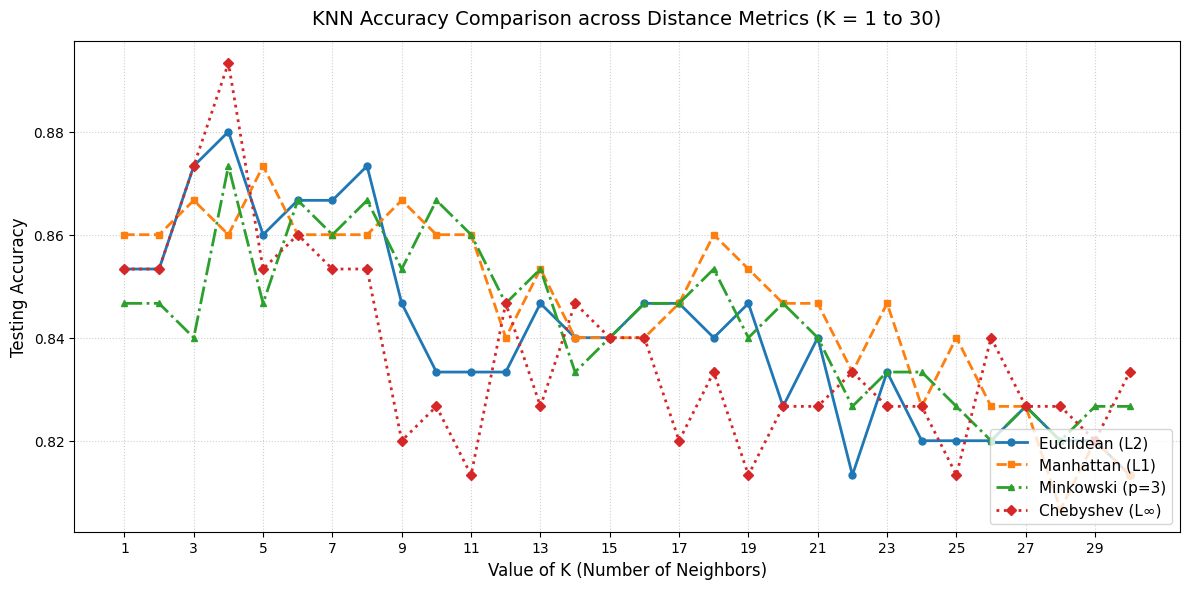

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ============================================================
# 1. Custom KNN Classifier Supporting Multiple Distance Metrics
# ============================================================

class MultiMetricKNN:
    """
    K-Nearest Neighbors Classifier supporting:
    - Distance Metrics: 'euclidean' (p=2), 'manhattan' (p=1), 'minkowski' (custom p), 'chebyshev' (p=inf)
    - Voting Methods: 'uniform', 'distance'
    """
    def __init__(self, k=5, metric='euclidean', p=3, weights='uniform', epsilon=1e-5):
        self.k = k
        self.metric = metric
        self.p = p  # Used when metric='minkowski'
        self.weights = weights
        self.epsilon = epsilon

    def fit(self, X, y):
        self.X_train = np.array(X)
        self.y_train = np.array(y)

    def _calculate_distance(self, x1, x2):
        """
        Compute distance between two points based on chosen metric.
        """
        if self.metric == 'euclidean':
            return np.sqrt(np.sum((x1 - x2) ** 2))
        elif self.metric == 'manhattan':
            return np.sum(np.abs(x1 - x2))
        elif self.metric == 'minkowski':
            return np.sum(np.abs(x1 - x2) ** self.p) ** (1.0 / self.p)
        elif self.metric == 'chebyshev':
            return np.max(np.abs(x1 - x2))
        else:
            raise ValueError(f"Unknown metric: {self.metric}")

    def _predict_single(self, x):
        # Step 1: Compute distances using selected metric
        distances = [self._calculate_distance(x, x_tr) for x_tr in self.X_train]

        # Step 2: Get indices of k nearest neighbors
        k_indices = np.argsort(distances)[:self.k]
        k_nearest_labels = [self.y_train[i] for i in k_indices]

        # Step 3: Vote based on weighting strategy
        if self.weights == 'uniform':
            most_common = Counter(k_nearest_labels).most_common(1)
            return most_common[0][0]

        elif self.weights == 'distance':
            k_distances = [distances[i] for i in k_indices]
            weights = [1.0 / (d + self.epsilon) for d in k_distances]
            class_weights = defaultdict(float)
            for label, w in zip(k_nearest_labels, weights):
                class_weights[label] += w
            return max(class_weights, key=class_weights.get)

    def predict(self, X):
        X = np.array(X)
        return np.array([self._predict_single(x) for x in X])

    def score(self, X, y):
        predictions = self.predict(X)
        return np.mean(predictions == y)


# ============================================================
# 2. Data Preparation
# ============================================================

X, y = make_classification(
    n_samples=500,
    n_features=5,
    n_informative=4,
    n_redundant=1,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# ============================================================
# 3. Model Evaluation across Metrics & K Values
# ============================================================

k_range = range(1, 31)
metrics = [
    ('euclidean', 'Euclidean (L2)', 'o', '-'),
    ('manhattan', 'Manhattan (L1)', 's', '--'),
    ('minkowski', 'Minkowski (p=3)', '^', '-.'),
    ('chebyshev', 'Chebyshev (L∞)', 'D', ':')
]

results = {}

for metric_key, label, marker, style in metrics:
    accuracies = []
    for k in k_range:
        # Evaluate using Minkowski metric with p=3 when applicable
        p_val = 3 if metric_key == 'minkowski' else 2

        knn = MultiMetricKNN(k=k, metric=metric_key, p=p_val, weights='distance')
        knn.fit(X_train, y_train)
        accuracies.append(knn.score(X_test, y_test))

    results[metric_key] = accuracies


# ============================================================
# 4. Comparative Plot Visualization
# ============================================================

plt.figure(figsize=(12, 6))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for idx, (metric_key, label, marker, style) in enumerate(metrics):
    plt.plot(
        k_range, results[metric_key],
        label=label,
        marker=marker,
        linestyle=style,
        color=colors[idx],
        linewidth=2,
        markersize=5
    )

plt.title('KNN Accuracy Comparison across Distance Metrics (K = 1 to 30)', fontsize=14, pad=12)
plt.xlabel('Value of K (Number of Neighbors)', fontsize=12)
plt.ylabel('Testing Accuracy', fontsize=12)
plt.xticks(range(1, 31, 2))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11, loc='lower right')

plt.tight_layout()
plt.show()